# RUKOPYS 06 — Formula + Table: Qwen3-VL-8B QLoRA (Stage 2, non-TrOCR branch)

Один ноутбук, який тренує **єдиний адаптер для `formula` і `table`** (гілка Qwen3-VL-8B зі Stage 2 вашого флоу). TrOCR / детекція / postprocessing сюди не входять.

**Що змінено порівняно з `05_Formula_Only` / `05_Table_Only`** (ці зміни — основа «найкращого рівня»):

| Було у 05 | Тут | Чому |
|---|---|---|
| Qwen3-VL-**4B**, T4 | Qwen3-VL-**8B** (як у флоу), профіль під GPU визначається автоматично | адаптер від 4B не переноситься на 8B |
| квадратний canvas 320×320 | **збереження пропорцій**, динамічний бюджет візуальних токенів (формула ≤768, таблиця ≤1536) | таблиці/довгі формули втрачали дрібні символи |
| 180×4=720 прикладів (<1 епохи), LR 1e-5 | **епохи**, eff. batch 16, LR 1e-4, cosine + warmup | реально навчається, а не «торкається» ваг |
| тільки GT-кропи | **jitter боксів + аугментації** (кропи від PP-DocLayoutV3 неточні) | прибирає domain shift між train і пайплайном |
| сира CER | **нормалізація тексту як в офіційній метриці** + per-region CER (як у score) | оптимізуємо те, що рахує Kaggle |
| 1 validation, відбір на ній | **train / dev (відбір чекпойнта) / test (один раз у кінці)**, page-disjoint | чесна фінальна цифра |
| нема baseline | **zero-shot baseline** на dev і test | видно реальний приріст |
| vision tower заморожений та квантований | vision tower **у bf16 + LoRA** (+ merger) | почерк — це перш за все візуальна адаптація |
| лише 4-bit перевірка | **перевірка у bf16** (так буде на H100) + `infer_formula_table.py` з **тим самим препроцесингом** | немає розсинхрону train/inference |

**Перед основним запуском** поставте `DRY_RUN=True` (клітинка 2): мініатюрний прогін усього шляху, щоб піймати помилки за ~15 хв, а не після години тренінгу.

> ⚠️ Усі числа CER тут — на ваших даних після запуску. Нічого не обіцяю наперед. «Ідеально» на рукописному тексті недосяжно — реальна ціль: максимально знизити CER на `test`.

## 1. Залежності та Drive

In [12]:
%pip -q uninstall -y torchao

In [13]:
%pip -q install "transformers>=4.57,<5" "accelerate>=1.10,<2" "peft>=0.17,<1" "bitsandbytes>=0.45" "huggingface_hub>=0.34,<2" pandas pillow tqdm rapidfuzz matplotlib
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB=True
except Exception:
    IN_COLAB=False
print('IN_COLAB =',IN_COLAB)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
IN_COLAB = True


## 2. Конфігурація (єдине місце, де треба щось міняти)

In [14]:
import os, json, math, random, hashlib, time, gc, shutil, re, sys, importlib.util, contextlib
from pathlib import Path
from collections import defaultdict, Counter
import numpy as np, pandas as pd, torch
from PIL import Image, ImageOps, ImageFilter, ImageEnhance
from tqdm.auto import tqdm
from huggingface_hub import hf_hub_download, HfApi

# ----------------------------- switches -----------------------------
DRY_RUN=False          # True = tiny end-to-end rehearsal. Do this FIRST.
USE_SILVER=False       # True = curriculum: silver (noisy) first, then gold. Enable only after checking audit + dev ablation.
SILVER_MAX=2000
RUN_BASELINE_TEST=True # zero-shot baseline on test (adapter disabled)
RUN_BF16_CHECK=True    # re-evaluate best adapter on a bf16 (non-quantized) base = what runs on H100
MERGE_EXPORT=False     # also save merged bf16 model (~16 GB on Drive)
INIT_ADAPTER=None      # path to an existing adapter trained on THE SAME base model (optional)
MODEL_ID_OVERRIDE=None # e.g. 'Qwen/Qwen3-VL-8B-Instruct'

SEED=42
HF_REPO='UkrainianCatholicUniversity/rukopys'
TASKS=('formula','table')
WORK=Path('/content/drive/MyDrive') if IN_COLAB else Path.home()/'rukopys_work'
ROOT=WORK/('rukopys_ft_qwen3vl8b_v1'+('_dry' if DRY_RUN else ''))
ROOT.mkdir(parents=True,exist_ok=True)
CACHE=Path('/content/rukopys_ft_cache' if IN_COLAB else str(Path.home()/'rukopys_cache'))/('dry' if DRY_RUN else 'full')
CACHE.mkdir(parents=True,exist_ok=True)
OLD_SPLIT_PATH=WORK/'rukopys_qwen_classifier_t4_224_v1'/'split.json'   # optional: reuse your old page-disjoint split
OFFICIAL_METRIC_FILE=ROOT/'official_metric.py'                          # optional: drop the official scorer here (see metric cell)

# ----------------------------- hardware profile -----------------------------
assert torch.cuda.is_available(),'Enable a GPU runtime (A100/H100/L4 recommended; T4 only for the 4B fallback)'
VRAM=torch.cuda.get_device_properties(0).total_memory/2**30
GPU=torch.cuda.get_device_name(0)
BF16=torch.cuda.is_bf16_supported()
DTYPE=torch.bfloat16 if BF16 else torch.float16
if VRAM>=60:   MODEL_ID,MICRO_BS,EVAL_BS,TOK_MAX='Qwen/Qwen3-VL-8B-Instruct',4,8,{'formula':768,'table':1536}
elif VRAM>=38: MODEL_ID,MICRO_BS,EVAL_BS,TOK_MAX='Qwen/Qwen3-VL-8B-Instruct',2,6,{'formula':640,'table':1280}
elif VRAM>=22: MODEL_ID,MICRO_BS,EVAL_BS,TOK_MAX='Qwen/Qwen3-VL-8B-Instruct',1,4,{'formula':512,'table':896}
else:          MODEL_ID,MICRO_BS,EVAL_BS,TOK_MAX='Qwen/Qwen3-VL-4B-Instruct',1,2,{'formula':384,'table':640}
if MODEL_ID_OVERRIDE: MODEL_ID=MODEL_ID_OVERRIDE
TOK_MIN={'formula':96,'table':192}   # small crops are upscaled to at least this many visual tokens (1 token = 32x32 px)
CTX_FRAC=0.12                        # context margin cached around every GT box (room for box jitter)

# ----------------------------- hyper-parameters -----------------------------
EPOCHS=3; EFF_BATCH=16
LR_LLM=1e-4; LR_VISION=5e-5; WEIGHT_DECAY=0.0; WARMUP_FRAC=0.05; MIN_LR_RATIO=0.1; MAX_GRAD_NORM=1.0
LORA_R=64; LORA_ALPHA=128; LORA_DROPOUT=0.05; TRAIN_VISION_LORA=True
MIN_TYPE_SHARE=0.35      # oversample the rarer class up to this share per epoch
DEV_PER_TASK=120         # dev samples per class used for checkpoint selection (greedy decoding)
EVALS_PER_EPOCH=2; PATIENCE=3; KEEP_LAST=2; MAX_ANSWER_TOKENS_CAP=1536
if DRY_RUN:
    EPOCHS=1; EFF_BATCH=MICRO_BS*2; DEV_PER_TASK=8; EVALS_PER_EPOCH=1; RUN_BF16_CHECK=False

# Prompts MUST stay identical between training and inference (they are saved to handoff.json).
PROMPTS={
 'formula':'Transcribe the handwritten mathematical formula(s) in this image exactly. Return only the transcription.',
 'table':'Transcribe the handwritten table in this image exactly. Separate cells in a row with " | " and rows with a newline. Return only the transcription.'}

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print(f'GPU={GPU} VRAM={VRAM:.1f} GiB bf16={BF16}\nMODEL={MODEL_ID}\nmicro_bs={MICRO_BS} eff_batch={EFF_BATCH} tok_max={TOK_MAX}\nROOT={ROOT}')
if 'Qwen3-VL-4B' in MODEL_ID: print('WARNING: 4B fallback. The adapter will NOT be loadable on the 8B model used in the pipeline.')
if not BF16: print('WARNING: no bf16 on this GPU; fp16 training of Qwen3-VL can overflow. Prefer A100/L4/H100.')

GPU=NVIDIA L4 VRAM=22.0 GiB bf16=True
MODEL=Qwen/Qwen3-VL-8B-Instruct
micro_bs=1 eff_batch=16 tok_max={'formula': 512, 'table': 896}
ROOT=/content/drive/MyDrive/rukopys_ft_qwen3vl8b_v1


## 3. Метрика: нормалізація як у змаганні + per-region CER
Офіційний скорер я звідси не бачу, тому нормалізація відтворена з таблиці правил на сторінці змагання (strikethrough, LaTeX-символи, латиниця→кирилиця для c/o/p/x, тире, лапки, степені/індекси, `x_{3}`→`x_3`, пробіли). **Список LaTeX-команд — наближений.** Якщо покласти офіційний файл у `official_metric.py` (шлях у конфігу) з функцією `normalize_text` / `normalize`, вона буде використана автоматично. Це впливає лише на *вимірювання*, не на тренування.

In [15]:
try:
    from rapidfuzz.distance import Levenshtein as _L
    lev=_L.distance
except Exception:
    def lev(a,b):
        if len(b)>len(a): a,b=b,a
        prev=list(range(len(b)+1))
        for i,ca in enumerate(a,1):
            cur=[i]
            for j,cb in enumerate(b,1): cur.append(min(cur[-1]+1,prev[j]+1,prev[j-1]+(ca!=cb)))
            prev=cur
        return prev[-1]

_LATEX={'alpha':'α','beta':'β','gamma':'γ','delta':'δ','epsilon':'ε','varepsilon':'ε','zeta':'ζ','eta':'η','theta':'θ','vartheta':'ϑ','iota':'ι','kappa':'κ',
 'lambda':'λ','mu':'μ','nu':'ν','xi':'ξ','pi':'π','rho':'ρ','sigma':'σ','tau':'τ','upsilon':'υ','phi':'φ','varphi':'φ','chi':'χ','psi':'ψ','omega':'ω',
 'Gamma':'Γ','Delta':'Δ','Theta':'Θ','Lambda':'Λ','Xi':'Ξ','Pi':'Π','Sigma':'Σ','Phi':'Φ','Psi':'Ψ','Omega':'Ω',
 'cdot':'·','times':'×','div':'÷','pm':'±','mp':'∓','leq':'≤','le':'≤','geq':'≥','ge':'≥','neq':'≠','ne':'≠','approx':'≈','equiv':'≡','sim':'∼',
 'infty':'∞','rightarrow':'→','to':'→','leftarrow':'←','leftrightarrow':'↔','Rightarrow':'⇒','Leftarrow':'⇐','Leftrightarrow':'⇔','in':'∈','notin':'∉',
 'subset':'⊂','supset':'⊃','cup':'∪','cap':'∩','emptyset':'∅','forall':'∀','exists':'∃','partial':'∂','nabla':'∇','sqrt':'√','sum':'∑','prod':'∏','int':'∫',
 'degree':'°','angle':'∠','perp':'⊥','parallel':'∥','ldots':'…','dots':'…','cdots':'⋯'}
_SUP=str.maketrans({'⁰':'^0','¹':'^1','²':'^2','³':'^3','⁴':'^4','⁵':'^5','⁶':'^6','⁷':'^7','⁸':'^8','⁹':'^9','⁺':'^+','⁻':'^-','ⁿ':'^n'})
_SUB=str.maketrans({'₀':'_0','₁':'_1','₂':'_2','₃':'_3','₄':'_4','₅':'_5','₆':'_6','₇':'_7','₈':'_8','₉':'_9','₊':'_+','₋':'_-'})
_LOOK=str.maketrans({'c':'с','o':'о','p':'р','x':'х'})

def approx_normalize(s):
    s=str(s)
    s=re.sub(r'~~(.*?)~~\{(.*?)\}',r'\2',s,flags=re.S)
    s=re.sub(r'~~(.*?)~~',r'\1',s,flags=re.S)
    s=re.sub(r'\\([A-Za-z]+)',lambda m:_LATEX.get(m.group(1),m.group(0)),s)
    s=s.translate(_LOOK)
    s=re.sub(r'[\u2013\u2014\u2212]','-',s)
    s=re.sub(r'[«»“”„]','"',s); s=re.sub(r'[‘’‚`]',"'",s)
    s=s.translate(_SUP).translate(_SUB)
    s=re.sub(r'([_^])\{([^{}\s]+)\}',r'\1\2',s)
    return re.sub(r'\s+',' ',s).strip()

NORMALIZER=approx_normalize; NORMALIZER_NAME='approximate (re-implemented from the rules table)'
if OFFICIAL_METRIC_FILE.exists():
    spec=importlib.util.spec_from_file_location('official_metric',OFFICIAL_METRIC_FILE); mod=importlib.util.module_from_spec(spec); spec.loader.exec_module(mod)
    for nm in ('normalize_text','normalize','normalise_text'):
        if callable(getattr(mod,nm,None)): NORMALIZER=getattr(mod,nm); NORMALIZER_NAME='OFFICIAL:'+nm; break
print('Normalizer:',NORMALIZER_NAME)
norm=lambda s:NORMALIZER(s)

def has_loop(s): return bool(re.search(r'(.{4,60}?)\1{4,}',s,flags=re.S))

def summarize(recs,scorable_only=True):
    sel=[x for x in recs if x['scorable']] if scorable_only else list(recs)
    out={}
    for kind in list(TASKS)+['all']:
        xs=[x for x in sel if kind=='all' or x['type']==kind]
        if not xs: continue
        refs=[norm(x['reference']) for x in xs]; preds=[norm(x['prediction']) for x in xs]
        d=[lev(a,b) for a,b in zip(refs,preds)]
        out[kind]={'n':len(xs),'CER_region':float(np.mean([di/max(1,len(a)) for di,a in zip(d,refs)])),
                   'CER_micro':sum(d)/max(1,sum(map(len,refs))),'EM':float(np.mean([a==b for a,b in zip(refs,preds)])),
                   'truncated':int(sum(bool(x['truncated']) for x in xs)),'empty':int(sum(not p for p in preds)),
                   'loops':int(sum(has_loop(x['prediction']) for x in xs))}
    return out

def selection_score(summ):   # lower is better; equal weight per class
    v=[summ[k]['CER_region'] for k in TASKS if k in summ]
    return float(np.mean(v)) if v else 9.9

Normalizer: approximate (re-implemented from the rules table)


## 4. Єдиний препроцесинг зображень (код **вставляється і в `infer_formula_table.py`**)
Це гарантує, що тренування, валідація й інференс масштабують кропи однаково: зберігаємо пропорції, кратність 32 px (patch 16 × merge 2), бюджет токенів на клас.

In [16]:
PREP_SRC = """
import math
from PIL import Image
PATCH_UNIT = 32  # Qwen3-VL: patch 16 x spatial merge 2 -> one visual token covers 32x32 px

def budget_resize(img, tok_min, tok_max):
    w, h = img.size
    hi = int(tok_max) * PATCH_UNIT * PATCH_UNIT
    lo = int(tok_min) * PATCH_UNIT * PATCH_UNIT
    px = w * h
    s = 1.0
    if px > hi: s = math.sqrt(hi / px)
    elif px < lo: s = min(math.sqrt(lo / px), 3.0)
    nw = max(PATCH_UNIT, int(round(w * s / PATCH_UNIT)) * PATCH_UNIT)
    nh = max(PATCH_UNIT, int(round(h * s / PATCH_UNIT)) * PATCH_UNIT)
    while nw * nh > hi and (nw > PATCH_UNIT or nh > PATCH_UNIT):
        if nw >= nh and nw > PATCH_UNIT: nw -= PATCH_UNIT
        elif nh > PATCH_UNIT: nh -= PATCH_UNIT
        else: nw -= PATCH_UNIT
    return img.convert('RGB').resize((nw, nh), Image.Resampling.BICUBIC)

def configure_processor(processor, max_tokens=4096):
    ip = processor.image_processor
    lo, hi = PATCH_UNIT * PATCH_UNIT * 4, PATCH_UNIT * PATCH_UNIT * max_tokens
    ip.size = {'shortest_edge': lo, 'longest_edge': hi}
    if hasattr(ip, 'min_pixels'): ip.min_pixels = lo
    if hasattr(ip, 'max_pixels'): ip.max_pixels = hi
    return processor
"""
exec(PREP_SRC)
# quick self-test
for k in TASKS:
    for sz in [(40,20),(300,60),(900,150),(4000,500),(2500,2500)]:
        im=budget_resize(Image.new('RGB',sz,'white'),TOK_MIN[k],TOK_MAX[k]); w,h=im.size
        assert w%32==0 and h%32==0 and (w*h)//1024<=TOK_MAX[k], (k,sz,im.size)
print('budget_resize OK')

budget_resize OK


In [17]:
from transformers import AutoProcessor
processor=AutoProcessor.from_pretrained(MODEL_ID)
configure_processor(processor,max_tokens=max(TOK_MAX.values())*2)
tok=processor.tokenizer
HDR=tok.encode('<|im_start|>assistant\n',add_special_tokens=False)
IM_END=tok.convert_tokens_to_ids('<|im_end|>'); EOT=tok.convert_tokens_to_ids('<|endoftext|>')
assert len(HDR)>=2 and IM_END is not None and IM_END>=0, (HDR,IM_END)
print('assistant header ids:',HDR,'| im_end:',IM_END,'| pad:',tok.pad_token_id)

assistant header ids: [151644, 77091, 198] | im_end: 151645 | pad: 151643


## 5. Дані: пін ревізії, page-disjoint split `train / dev / test`
* `dev` — вибір чекпойнта під час тренінгу; `test` — **один раз** у кінці (чесна цифра).
* Якщо є ваш старий `split.json`, береться він (його `train` лишається `train`, а `validation` ділиться навпіл на dev/test за хешем сторінки). Інакше — новий split, стратифікований за джерелом.
* Спліт зберігається у `ROOT/split.json` і більше не змінюється (захист від витоку при перезапуску).

In [18]:
api=HfApi()
repo_files=api.list_repo_files(HF_REPO,repo_type='dataset')
print('top-level:',dict(Counter(f.split('/')[0] for f in repo_files)))
print('metadata files:',[f for f in repo_files if f.endswith('metadata.jsonl')])

split_path=ROOT/'split.json'
saved=json.loads(split_path.read_text(encoding='utf-8')) if split_path.exists() else None
old=json.loads(OLD_SPLIT_PATH.read_text(encoding='utf-8')) if (saved is None and OLD_SPLIT_PATH.is_file()) else None
REVISION=(saved or old or {}).get('dataset_revision') or api.dataset_info(HF_REPO).sha
meta_path=Path(hf_hub_download(repo_id=HF_REPO,filename='train/metadata.jsonl',repo_type='dataset',revision=REVISION))
meta_sha=hashlib.sha256(meta_path.read_bytes()).hexdigest()
if saved: assert saved['metadata_sha256']==meta_sha,'metadata changed vs saved split'
if old and old.get('metadata_sha256'): assert old['metadata_sha256']==meta_sha,'old split does not match this metadata'
records=[json.loads(l) for l in meta_path.read_text(encoding='utf-8').splitlines() if l.strip()]
print('revision',REVISION,'| pages:',len(records))

def stable(x): return hashlib.sha256(f'{SEED}|{x}'.encode()).hexdigest()

def parse(recs,src):
    rows=[];bad=Counter()
    for rec in recs:
        for idx,reg in enumerate(rec.get('regions',[])):
            if reg.get('type') not in TASKS: continue
            b=reg.get('bbox'); t=reg.get('text')
            try:
                b=[float(v) for v in b]
                if len(b)!=4 or not all(math.isfinite(v) for v in b) or b[2]<=b[0] or b[3]<=b[1]: raise ValueError
            except Exception: bad['bad_bbox']+=1; continue
            if not isinstance(t,str) or not t.strip(): bad['blank_text']+=1; continue
            lang,leg=reg.get('language'),reg.get('legibility')
            rows.append({'key':f"{src}|{rec['file_name']}::{idx}",'src':src,'page':rec['file_name'],'idx':idx,'type':reg['type'],
                'text':t.strip(),'gt_box':b,'source':rec.get('source','unknown'),'language':lang,'legibility':leg,
                'scorable':(lang in (None,'uk')) and (leg in (None,'legible')),   # mirrors the official scorable rule
                'trainable':leg in (None,'legible')})
    return rows,bad
rows_all,bad=parse(records,'train'); print('skipped:',dict(bad))
page_src={r['page']:r['source'] for r in rows_all}

if saved: split=saved
else:
    pages=sorted(page_src)
    if old:
        tr=set(old['train']); va=sorted(p for p in pages if p in set(old['validation']))
        split={'train':sorted(p for p in pages if p in tr),'dev':[p for p in va if int(stable(p),16)%2==0],'test':[p for p in va if int(stable(p),16)%2==1]}
        origin='derived from old classifier split'
    else:
        split={'train':[],'dev':[],'test':[]}; by=defaultdict(list)
        for p in pages: by[page_src[p]].append(p)
        for s,ps in by.items():
            ps=sorted(ps,key=stable); n=len(ps); nt=int(round(.1*n)); nd=int(round(.1*n))
            if n>=6: nt=max(nt,1); nd=max(nd,1)
            split['test']+=ps[:nt]; split['dev']+=ps[nt:nt+nd]; split['train']+=ps[nt+nd:]
        origin='new, stratified by source'
    split.update({'dataset_revision':REVISION,'metadata_sha256':meta_sha,'origin':origin})
    split_path.write_text(json.dumps(split,ensure_ascii=False,indent=1),encoding='utf-8')
part_of={p:k for k in ('train','dev','test') for p in split[k]}
assert len(part_of)==sum(len(split[k]) for k in ('train','dev','test')),'a page is in two partitions!'
for r in rows_all: r['part']=part_of.get(r['page'],'unassigned')
rows_all=[r for r in rows_all if r['part']!='unassigned']
print('split origin:',split.get('origin'),{k:len(split[k]) for k in ('train','dev','test')})

# ---- optional silver split (auto-detected) ----
silver_all=[]
if USE_SILVER:
    if 'silver/metadata.jsonl' in repo_files:
        sp=Path(hf_hub_download(repo_id=HF_REPO,filename='silver/metadata.jsonl',repo_type='dataset',revision=REVISION))
        srecs=[json.loads(l) for l in sp.read_text(encoding='utf-8').splitlines() if l.strip()]
        silver_all,_=parse(srecs,'silver')
        silver_all=[r for r in silver_all if r['page'] not in part_of and r['trainable']]
        for r in silver_all: r['part']='silver'
        print('silver formula/table regions:',Counter(r['type'] for r in silver_all))
    else:
        print('USE_SILVER=True but silver/metadata.jsonl not found in the repo -> silver disabled'); USE_SILVER=False

top-level: {'.gitattributes': 1, 'README.md': 1, 'sample_submission.csv': 1, 'silver': 8931, 'test': 383, 'train': 1331}
metadata files: ['silver/metadata.jsonl', 'test/metadata.jsonl', 'train/metadata.jsonl']
revision 8217bf9a5189f5ce919de99e32e5db7bab37fc17 | pages: 1330
skipped: {'blank_text': 1}
split origin: derived from old classifier split {'train': 300, 'dev': 32, 'test': 32}


## 6. Аудит: що саме лежить у GT (дивіться на це очима!)
Тут видно, чи таблиці справді з `|`, які мови/розбірливість, скільки даних, довжини в токенах і чи немає дублікатів тексту між train і dev/test. **Від цього залежить, чи правильні промпти.**

In [19]:
frame=pd.DataFrame(rows_all)
print('regions by partition x type'); display(pd.crosstab(frame.part,frame.type))
print('language / legibility (by type)'); display(frame.groupby(['type','language','legibility'],dropna=False).size().unstack(fill_value=0))
print('sources (train)'); display(pd.crosstab(frame[frame.part=='train'].source,frame[frame.part=='train'].type))

tbl=frame[frame.type=='table'].text
if len(tbl):
    ps,ns=tbl.str.contains(r'\|',regex=True).mean(),tbl.str.contains('\n').mean()
    print(f'TABLE GT: contains "|" in {ps:.0%}, contains newline in {ns:.0%}')
    if ps<0.5: print('!!! Most table GT has no "|": the TABLE prompt/format assumption is wrong -> adapt PROMPTS["table"] before training.')
for k in TASKS:
    print('\n==',k.upper(),'examples');
    for t in frame[(frame.type==k)&(frame.part=='train')].text.head(4): print(repr(t[:300]))

# token lengths of targets (determines generation budgets and filters overlong samples)
for r in rows_all+silver_all: r['ans_tokens']=len(tok.encode(r['text'],add_special_tokens=False))+2
tl=pd.DataFrame(rows_all); print('\nanswer tokens (train):'); display(tl[tl.part=='train'].groupby('type').ans_tokens.describe(percentiles=[.5,.9,.95,.99]))
p99=int(tl[tl.part=='train'].ans_tokens.quantile(.99))
MAX_ANSWER_TOKENS=min(MAX_ANSWER_TOKENS_CAP,p99+16)
GEN_TOKENS={k:min(2048,int(math.ceil(tl[(tl.type==k)].ans_tokens.quantile(.995)*1.25))+16) for k in TASKS}
print('MAX_ANSWER_TOKENS (train filter) =',MAX_ANSWER_TOKENS,'| generation budgets =',GEN_TOKENS)

tr_texts={norm(r['text']) for r in rows_all if r['part']=='train'}
for k in ('dev','test'):
    xs=[r for r in rows_all if r['part']==k]
    if xs: print(f'{k}: {np.mean([norm(r["text"]) in tr_texts for r in xs]):.1%} of reference texts also occur verbatim in train (high = repeated templates, CER will look optimistic)')

regions by partition x type


type,formula,table
part,,
dev,247,6
test,230,14
train,2414,122


language / legibility (by type)


legibility        illegible  legible
type    language                    
formula other             0      242
        uk                3     2646
table   other             0        7
        uk                0      135

sources (train)


type,formula,table
source,,
archive,0,1
school,1512,118
university,902,3


TABLE GT: contains "|" in 74%, contains newline in 75%

== FORMULA examples
'6) R2 ⊕ R1'
'R_2 ⊕ R_1 = {(b, c), (e, b), (e, a), (a, d), (d, e), (d, c)}'
'R_2^{-1} = {(b, a), (d, a), (e, d), (e, d)}'
'~~1.~~3. ~~L~~ a(1;1;1) b=(2;-1;1)'

== TABLE examples
'№№ п/п | Учрежд. | Полагается | Выдан | Остает | Примечание\n1 | Фав. К-сія | молоко. 40 | мыло 85 | масл. 17 | 40 | 85 | 17 | | \n2 | Лит.клуб.. | 40 | 85 | 16 | 40 | 85 | 16 | - | - | - \n3 | Площадки | 31 1/2 | 40 | | 31 1/2 | 40 | ) 46 1/2\n4 | Почаевской, 23 | 47/4г- 4 2/1 | 350 | | 47 1/2 - 4 2/1 '
'Гапузь | Експорт країни, млн USD | експорт світу, млн USD\nМода та текстиль | 400 | 2000\nХарчова промисловість | 350 | 15000 \nАвтомобільне будування | 250 | 12 000\nТуристичні послуги | 500 | 25 000\nВина та напої | 300 | 1000'
'Множина | 10 | 11 | 12 | 13 | 14\nB | 0 | 0 | 1 | 1 | 1\nC | 1 | 0 | 0 | 0 | 1\nB ∩ C | 0 | 1\nU \\ (B ∩ C) | 1 | 0\nD | 0 | 0 | 1 | 0 | 0\nРезультат | 1 | 1 | 0 | 1 | 0'
'|x|y|z|x y z|x y z|x y z|f(x y z)\n

,count,mean,std,min,50%,90%,95%,99%,max
type,,,,,,,,,
formula,2414.0,24.060066,19.823718,3.0,18.0,46.0,62.35,100.00,199.0
table,122.0,58.647541,67.447552,9.0,31.5,124.6,176.85,330.32,437.0


MAX_ANSWER_TOKENS (train filter) = 138 | generation budgets = {'formula': 173, 'table': 470}
dev: 9.5% of reference texts also occur verbatim in train (high = repeated templates, CER will look optimistic)
test: 5.7% of reference texts also occur verbatim in train (high = repeated templates, CER will look optimistic)


In [20]:
train_rows=sorted([r for r in rows_all if r['part']=='train' and r['trainable'] and r['ans_tokens']<=MAX_ANSWER_TOKENS],key=lambda r:stable(r['key']))
dropped=sum(1 for r in rows_all if r['part']=='train')-len(train_rows)
dev_pool=sorted([r for r in rows_all if r['part']=='dev' and r['scorable']],key=lambda r:stable(r['key']))
dev_rows=[x for k in TASKS for x in [r for r in dev_pool if r['type']==k][:DEV_PER_TASK]]
test_rows=sorted([r for r in rows_all if r['part']=='test'],key=lambda r:stable(r['key']))
silver_rows=sorted([r for r in silver_all if r['ans_tokens']<=MAX_ANSWER_TOKENS],key=lambda r:stable(r['key']))[:SILVER_MAX] if USE_SILVER else []
if DRY_RUN:
    train_rows=[x for k in TASKS for x in [r for r in train_rows if r['type']==k][:2*MICRO_BS*2]]
    test_rows=[x for k in TASKS for x in [r for r in test_rows if r['type']==k][:8]]; silver_rows=[]
assert train_rows and dev_rows and test_rows,'empty partition'
print(f'train={len(train_rows)} (dropped {dropped} untrainable/overlong) | dev={len(dev_rows)} | test={len(test_rows)} | silver={len(silver_rows)}')
print('train by type:',dict(Counter(r['type'] for r in train_rows)),'| dev:',dict(Counter(r['type'] for r in dev_rows)),'| test:',dict(Counter(r['type'] for r in test_rows)))
assert not ({r['page'] for r in train_rows}&{r['page'] for r in dev_rows+test_rows}) and not ({r['page'] for r in dev_rows}&{r['page'] for r in test_rows})
ROW_BY_KEY={r['key']:r for r in train_rows+dev_rows+test_rows+silver_rows}

train=2518 (dropped 18 untrainable/overlong) | dev=124 | test=244 | silver=0
train by type: {'formula': 2406, 'table': 112} | dev: {'formula': 120, 'table': 4} | test: {'formula': 230, 'table': 14}


## 7. Кеш кропів **з контекстним полем** (потрібне для jitter боксів)
Кожен GT-бокс зберігається з полем 12 % з кожного боку. Під час тренінгу бокс випадково розширюється/зсувається, імітуючи неточний PP-DocLayoutV3. Сторінки качаються паралельно.

In [21]:
from concurrent.futures import ThreadPoolExecutor, as_completed
meta_lookup={r['file_name']:r for r in records}
def uid_of(row): return hashlib.sha256(row['key'].encode()).hexdigest()[:24]
def crop_file(row): return CACHE/'crops'/row['part']/(uid_of(row)+'.jpg')
def side_file(row): return crop_file(row).with_suffix('.json')
def pad_box(b,W,H):
    x1,y1,x2,y2=b; mx=max(12,CTX_FRAC*(x2-x1)); my=max(12,CTX_FRAC*(y2-y1))
    return [max(0,math.floor(x1-mx)),max(0,math.floor(y1-my)),min(W,math.ceil(x2+mx)),min(H,math.ceil(y2+my))]
def page_path(src,page):
    p=Path(page)
    if p.is_absolute() or '..' in p.parts or not p.parts or p.parts[0]!='images': raise ValueError(f'unexpected page path {page}')
    return Path(hf_hub_download(repo_id=HF_REPO,filename=f'{"train" if src=="train" else "silver"}/{p.as_posix()}',repo_type='dataset',revision=REVISION))
def process_page(src,page,rows):
    todo=[r for r in rows if not (crop_file(r).exists() and side_file(r).exists())]
    if not todo: return []
    errs=[]
    with Image.open(page_path(src,page)) as original:
        img=original.convert('RGB'); exp=(meta_lookup.get(page,{}).get('image_width'),meta_lookup.get(page,{}).get('image_height'))
        if all(exp) and img.size!=tuple(exp):
            rot=ImageOps.exif_transpose(original).convert('RGB')
            if rot.size==tuple(exp): img=rot
        W,H=img.size
        for r in todo:
            gb=r['gt_box']; cb=pad_box(gb,W,H)
            if cb[2]<=cb[0] or cb[3]<=cb[1]: errs.append((r['key'],'bad crop box')); continue
            crop_file(r).parent.mkdir(parents=True,exist_ok=True)
            img.crop(tuple(cb)).save(crop_file(r),quality=95)
            side_file(r).write_text(json.dumps({'cache_box':cb,'gt_box':[min(max(gb[0],0),W),min(max(gb[1],0),H),min(gb[2],W),min(gb[3],H)]}))
    return errs
groups=defaultdict(list)
for r in train_rows+dev_rows+test_rows+silver_rows: groups[(r['src'],r['page'])].append(r)
errors=[]
with ThreadPoolExecutor(max_workers=8) as ex:
    futs={ex.submit(process_page,s,p,rs):(s,p) for (s,p),rs in groups.items()}
    for f in tqdm(as_completed(futs),total=len(futs),desc='pages -> crops'):
        try: errors+=f.result()
        except Exception as e: errors.append((futs[f],str(e)))
print('errors:',len(errors),errors[:5])
bad_keys=set()
for e in errors:
    k=e[0]
    if isinstance(k,tuple): bad_keys|={r['key'] for r in groups[k]}
    else: bad_keys.add(k)
if len(bad_keys)>0.02*len(ROW_BY_KEY): raise RuntimeError(f'{len(bad_keys)} rows failed (>2%): fix data access before training')
def alive(rs): return [r for r in rs if r['key'] not in bad_keys and crop_file(r).exists() and side_file(r).exists()]
train_rows,dev_rows,test_rows,silver_rows=map(alive,(train_rows,dev_rows,test_rows,silver_rows))
for r in train_rows+dev_rows+test_rows+silver_rows:
    r.update(json.loads(side_file(r).read_text())); r['crop_path']=str(crop_file(r))
ROW_BY_KEY={r['key']:r for r in train_rows+dev_rows+test_rows+silver_rows}
print(f'ready: train={len(train_rows)} dev={len(dev_rows)} test={len(test_rows)} silver={len(silver_rows)} | dropped {len(bad_keys)}')

pages -> crops:   0%|          | 0/353 [00:00<?, ?it/s]

errors: 0 []
ready: train=2518 dev=124 test=244 silver=0 | dropped 0


## 8. Входи моделі: jitter боксу, аугментації, маскування лейблів (loss лише на відповіді)
* **train**: випадкові відхилення кожної сторони боксу (розширення до 12 %, стиснення до 3 %), 15 % часу — точний GT-бокс; легкий поворот, яскравість/контраст, blur, зниження якості, JPEG; випадковий бюджет токенів 75–100 %.
* **eval `gt`**: точний GT-бокс. **eval `det`**: детермінований «детекторний» шум (розширення до 8 %, стиснення до 2 %) — найближче до реального пайплайну. Відбір чекпойнта йде по `det`.

batch keys: ['input_ids', 'attention_mask', 'pixel_values', 'image_grid_thw', 'labels'] | ids (2, 506) | grid [[1, 26, 70], [1, 6, 60]]
SUPERVISED TEXT : 'X = ( 2-3\\0+1 11-9\\0+3)<|im_end|>'
REFERENCE       : 'X = ( 2-3\\0+1 11-9\\0+3)'


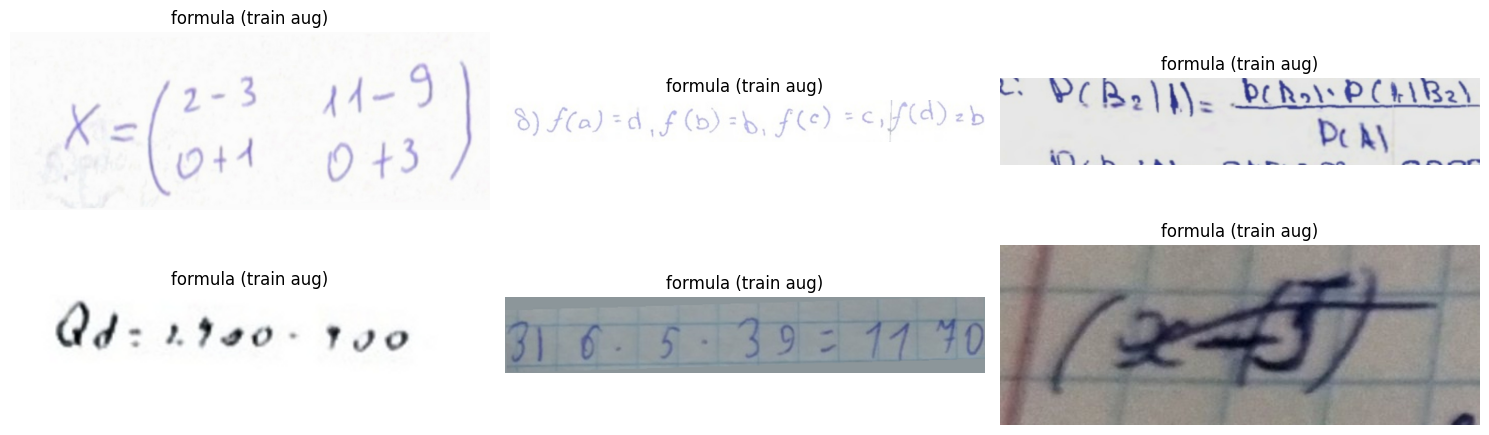

In [22]:
import io
def jitter_box(box,W,H,rng,expand,shrink):
    x1,y1,x2,y2=box; w,h=x2-x1,y2-y1
    nb=[x1-rng.uniform(-shrink,expand)*w, y1-rng.uniform(-shrink,expand)*h, x2+rng.uniform(-shrink,expand)*w, y2+rng.uniform(-shrink,expand)*h]
    nb=[max(0,nb[0]),max(0,nb[1]),min(W,nb[2]),min(H,nb[3])]
    if nb[2]-nb[0]<8 or nb[3]-nb[1]<8: return [max(0,x1),max(0,y1),min(W,x2),min(H,y2)]
    return nb

def load_view(row,mode,rng=None):
    with Image.open(row['crop_path']) as _im: im=_im.convert('RGB')
    W,H=im.size; ox,oy=row['cache_box'][:2]; g=row['gt_box']
    gt=[g[0]-ox,g[1]-oy,g[2]-ox,g[3]-oy]
    if mode=='gt': box=gt
    elif mode=='det': box=jitter_box(gt,W,H,random.Random('det|'+row['key']),0.08,0.02)
    else: box=gt if rng.random()<0.15 else jitter_box(gt,W,H,rng,0.12,0.03)
    return im.crop(tuple(int(round(v)) for v in box))

def augment(img,rng):
    w,h=img.size; px=[img.getpixel((0,0)),img.getpixel((w-1,0)),img.getpixel((0,h-1)),img.getpixel((w-1,h-1))]
    bg=tuple(int(sum(p[c] for p in px)/4) for c in range(3))
    if rng.random()<0.5: img=img.rotate(rng.uniform(-2,2),expand=True,fillcolor=bg,resample=Image.Resampling.BICUBIC)
    if rng.random()<0.7:
        img=ImageEnhance.Brightness(img).enhance(rng.uniform(.75,1.25)); img=ImageEnhance.Contrast(img).enhance(rng.uniform(.75,1.3)); img=ImageEnhance.Color(img).enhance(rng.uniform(.7,1.2))
    if rng.random()<0.25:
        f=rng.uniform(.5,.9); img=img.resize((max(8,int(img.width*f)),max(8,int(img.height*f))),Image.Resampling.BILINEAR)
    if rng.random()<0.2: img=img.filter(ImageFilter.GaussianBlur(rng.uniform(.3,1.1)))
    if rng.random()<0.3:
        b=io.BytesIO(); img.save(b,'JPEG',quality=rng.randint(50,90)); b.seek(0); img=Image.open(b).convert('RGB')
    return img

def train_image(row,rng):
    img=augment(load_view(row,'train',rng),rng)
    return budget_resize(img,TOK_MIN[row['type']],max(TOK_MIN[row['type']]+1,int(TOK_MAX[row['type']]*rng.uniform(.75,1.0))))
def eval_image(row,mode): return budget_resize(load_view(row,mode),TOK_MIN[row['type']],TOK_MAX[row['type']])

def build_text(kind,answer=None):
    m=[{'role':'user','content':[{'type':'image'},{'type':'text','text':PROMPTS[kind]}]}]
    if answer is not None: m.append({'role':'assistant','content':[{'type':'text','text':answer}]})
    return processor.apply_chat_template(m,tokenize=False,add_generation_prompt=(answer is None))

def find_last(seq,pat):
    n=len(pat)
    for i in range(len(seq)-n,-1,-1):
        if seq[i:i+n]==pat: return i
    return -1

_grid_checks=[0]
def check_grid(batch,imgs):
    if _grid_checks[0]>=20: return
    _grid_checks[0]+=1
    for g,im in zip(batch['image_grid_thw'].tolist(),imgs):
        if (g[1]*16,g[2]*16)!=(im.height,im.width): raise RuntimeError(f'Processor resized the image (grid {g} vs {im.size}); check configure_processor / transformers version')

def collate_train(rows,rng):
    imgs=[train_image(r,rng) for r in rows]; texts=[build_text(r['type'],r['text']) for r in rows]
    tok.padding_side='right'
    b=processor(text=texts,images=imgs,padding=True,return_tensors='pt'); b.pop('token_type_ids',None); check_grid(b,imgs)
    ids=b['input_ids']; lab=ids.clone(); lab[b['attention_mask']==0]=-100
    for i in range(len(rows)):
        seq=ids[i].tolist(); s=find_last(seq,HDR)
        if s<0: raise RuntimeError('assistant header not found in sample')
        lab[i,:s+len(HDR)]=-100
        e=max(j for j,t in enumerate(seq) if t==IM_END); lab[i,e+1:]=-100
        if int((lab[i]!=-100).sum())<2: raise RuntimeError('no supervised tokens')
    b['labels']=lab
    return b

# ---- sanity: look at one real batch (text, masking, image sizes) ----
_rng=random.Random(0); _b=collate_train(train_rows[:min(2,len(train_rows))],_rng)
print('batch keys:',list(_b.keys()),'| ids',tuple(_b['input_ids'].shape),'| grid',_b['image_grid_thw'].tolist())
_i=0; sup=_b['labels'][_i][_b['labels'][_i]!=-100]
print('SUPERVISED TEXT :',repr(tok.decode(sup)[:300])); print('REFERENCE       :',repr(train_rows[_i]['text'][:300]))
import matplotlib.pyplot as plt
fig,ax=plt.subplots(2,3,figsize=(15,5))
for j,a in enumerate(ax.ravel()):
    r=train_rows[j%len(train_rows)]; a.imshow(train_image(r,random.Random(j))); a.set_title(r['type']+' (train aug)'); a.axis('off')
plt.tight_layout(); plt.show()

## 9. Модель: 4-bit NF4 база, **vision tower у bf16 + LoRA** на LLM і vision
* `visual` та `lm_head` не квантуються (дрібні штрихи почерку чутливі до квантування vision).
* LoRA: усі лінійні шари LLM (`q,k,v,o,gate,up,down`) + vision-блоки (`attn.qkv/proj`, `mlp.linear_fc1/2`) + merger-и. Є перевірка, що регулярка справді знайшла модулі.

In [23]:
from transformers import Qwen3VLForConditionalGeneration, BitsAndBytesConfig
from peft import LoraConfig, PeftModel, get_peft_model, set_peft_model_state_dict
from peft.utils.save_and_load import load_peft_weights

quant=BitsAndBytesConfig(load_in_4bit=True,bnb_4bit_quant_type='nf4',bnb_4bit_compute_dtype=DTYPE,bnb_4bit_use_double_quant=True,
                         llm_int8_skip_modules=['visual','lm_head'])
base=Qwen3VLForConditionalGeneration.from_pretrained(MODEL_ID,quantization_config=quant,device_map={'':0},torch_dtype=DTYPE,attn_implementation='sdpa')
base.config.use_cache=False
base.gradient_checkpointing_enable(gradient_checkpointing_kwargs={'use_reentrant':False})
try: base.enable_input_require_grads()
except Exception as e: print('enable_input_require_grads skipped:',e)

LLM_RE=r'language_model\.layers\.\d+\.(self_attn\.(q_proj|k_proj|v_proj|o_proj)|mlp\.(gate_proj|up_proj|down_proj))'
VIS_RE=r'visual\.(blocks\.\d+\.(attn\.(qkv|proj)|mlp\.(linear_fc1|linear_fc2))|merger\.linear_fc[12]|deepstack_merger_list\.\d+\.linear_fc[12])'
TARGET=r'.*('+LLM_RE+('|'+VIS_RE if TRAIN_VISION_LORA else '')+')'
if INIT_ADAPTER:
    model=PeftModel.from_pretrained(base,str(INIT_ADAPTER),is_trainable=True); print('Initialized from',INIT_ADAPTER)
else:
    model=get_peft_model(base,LoraConfig(r=LORA_R,lora_alpha=LORA_ALPHA,lora_dropout=LORA_DROPOUT,target_modules=TARGET,bias='none',task_type='CAUSAL_LM'))
lora_names=[n for n,_ in model.named_modules() if n.endswith('lora_A.default')]
n_llm=sum('language_model' in n for n in lora_names); n_vis=sum('visual' in n for n in lora_names)
print(f'LoRA modules: LLM={n_llm}, vision={n_vis}')
assert n_llm>0 and (n_vis>0 or not TRAIN_VISION_LORA),'LoRA target regex matched nothing -> module names differ in this transformers version'
model.print_trainable_parameters()
print('peak after load GiB:',round(torch.cuda.max_memory_allocated()/2**30,2))

Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

LoRA modules: LLM=252, vision=116
trainable params: 209,975,296 || all params: 8,977,098,992 || trainable%: 2.3390
peak after load GiB: 14.25


## 10. Інференс-обв’язка (батчевий greedy) + `evaluate()` з кешем у JSONL
Кожен прогноз пишеться в `ROOT/evaluation/*.jsonl` одразу, тому обрив Colab не втрачає роботу. Truncation (немає `<|im_end|>`) і цикли-повтори рахуються окремо.

In [24]:
def load_jsonl(p):
    d={}
    if p.exists():
        for line in p.read_text(encoding='utf-8').splitlines():
            try: x=json.loads(line); d[x['ek']]=x
            except Exception: pass
    return d

@torch.inference_mode()
def generate_batch(rows,mode,max_new):
    imgs=[eval_image(r,mode) for r in rows]; texts=[build_text(r['type']) for r in rows]
    tok.padding_side='left'
    b=processor(text=texts,images=imgs,padding=True,return_tensors='pt'); b.pop('token_type_ids',None); check_grid(b,imgs); b=b.to('cuda')
    out=model.generate(**b,max_new_tokens=max_new,do_sample=False,use_cache=True,pad_token_id=tok.pad_token_id)
    gen=out[:,b['input_ids'].shape[1]:]
    done=((gen==IM_END)|(gen==EOT)).any(dim=1).tolist()
    return [t.strip() for t in tok.batch_decode(gen,skip_special_tokens=True)],[not d for d in done]

def safe_generate(chunk,mode,max_new):
    try: return generate_batch(chunk,mode,max_new)
    except torch.cuda.OutOfMemoryError:
        torch.cuda.empty_cache()
        if len(chunk)==1: raise
        a=safe_generate(chunk[:len(chunk)//2],mode,max_new); c=safe_generate(chunk[len(chunk)//2:],mode,max_new)
        return a[0]+c[0],a[1]+c[1]

def evaluate(rows,mode,tag,adapter=True):
    path=ROOT/'evaluation'/f'{tag}.jsonl'; path.parent.mkdir(parents=True,exist_ok=True)
    prior=load_jsonl(path); ek=lambda r:f"{r['key']}#{mode}"
    need=[r for r in rows if ek(r) not in prior]
    if need:
        was_training=model.training; model.eval()
        ctx=contextlib.nullcontext() if adapter else model.disable_adapter()
        with ctx, path.open('a',encoding='utf-8') as f:
            for kind in TASKS:
                rs=sorted([r for r in need if r['type']==kind],key=lambda r:(r['gt_box'][2]-r['gt_box'][0])*(r['gt_box'][3]-r['gt_box'][1]))
                for i in tqdm(range(0,len(rs),EVAL_BS),desc=f'{tag}:{kind}',leave=False):
                    chunk=rs[i:i+EVAL_BS]; texts,trunc=safe_generate(chunk,mode,GEN_TOKENS[kind])
                    for r,t,tr in zip(chunk,texts,trunc):
                        x={'ek':ek(r),'key':r['key'],'mode':mode,'type':r['type'],'reference':r['text'],'prediction':t,'truncated':bool(tr),'scorable':r['scorable'],'source':r['source']}
                        f.write(json.dumps(x,ensure_ascii=False)+'\n'); prior[x['ek']]=x
            f.flush()
        if was_training: model.train()
    return [prior[ek(r)] for r in rows]

def activate(path):
    set_peft_model_state_dict(model,load_peft_weights(str(path),device='cpu'),adapter_name='default'); model.eval()

def show(tag,summ):
    df=pd.DataFrame([{'run':tag,'class':k,**v} for k,v in summ.items()]); display(df.round(4)); return df

# ---- zero-shot baseline on dev (LoRA B=0 at init == base model; adapter disabled to be explicit) ----
base_dev=summarize(evaluate(dev_rows,'det','dev_det_baseline',adapter=False)); _=show('baseline zero-shot (dev, det boxes)',base_dev)
BASELINE_DEV_SCORE=selection_score(base_dev); print('baseline dev score (mean region CER, lower=better):',round(BASELINE_DEV_SCORE,4))

dev_det_baseline:formula:   0%|          | 0/30 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


dev_det_baseline:table:   0%|          | 0/1 [00:00<?, ?it/s]

,run,class,n,CER_region,CER_micro,EM,truncated,empty,loops
0,"baseline zero-shot (dev, det boxes)",formula,120,0.3290,0.2446,0.0833,0,0,0
1,"baseline zero-shot (dev, det boxes)",table,4,0.6055,0.4765,0.0000,0,0,0
2,"baseline zero-shot (dev, det boxes)",all,124,0.3380,0.2792,0.0806,0,0,0


baseline dev score (mean region CER, lower=better): 0.4673


## 11. Smoke-тест найгіршого батчу (пам'ять) і план тренінгу
Беремо `MICRO_BS` найдовших/найважчих прикладів, робимо forward+backward і друкуємо піковий VRAM. Якщо OOM — зменшіть `MICRO_BS` або `TOK_MAX` (клітинка 2). Далі будується **детермінований порядок прикладів** (епохи + дозаповнення рідшого класу + опційно silver першим), тому відновлення з чекпойнта точно продовжує з того самого місця.

In [25]:
pool=train_rows+silver_rows
worst=sorted(pool,key=lambda r:r['ans_tokens']+TOK_MAX[r['type']],reverse=True)[:MICRO_BS]
model.train(); model.zero_grad(set_to_none=True); torch.cuda.reset_peak_memory_stats()
try:
    b=collate_train(worst,random.Random(1)).to('cuda')
    with torch.autocast('cuda',dtype=DTYPE): l=model(**b).loss
    assert torch.isfinite(l); l.backward(); torch.cuda.synchronize()
    print(f'SMOKE PASS | loss={float(l):.3f} | seq_len={b["input_ids"].shape[1]} | peak VRAM={torch.cuda.max_memory_allocated()/2**30:.1f} GiB of {VRAM:.0f}')
    if torch.cuda.max_memory_allocated()/2**30>0.92*VRAM: print('!!! very close to the VRAM limit: lower MICRO_BS or TOK_MAX')
except torch.cuda.OutOfMemoryError:
    raise RuntimeError('OOM in worst-case batch: lower MICRO_BS or TOK_MAX in the config cell')
finally:
    model.zero_grad(set_to_none=True);
    for n in ('b','l'): globals().pop(n,None)
    gc.collect(); torch.cuda.empty_cache()

def build_order():
    order=[]
    if USE_SILVER and silver_rows:
        rs=np.random.RandomState(SEED); order+=[silver_rows[i] for i in rs.permutation(len(silver_rows))]
    byt={k:[r for r in train_rows if r['type']==k] for k in TASKS}
    for ep in range(EPOCHS):
        rs=np.random.RandomState(SEED+1+ep); ep_rows=list(train_rows)
        counts={k:len(v) for k,v in byt.items()}; minority=min(counts,key=counts.get); major=max(counts.values()); m=counts[minority]
        if m>0 and m/(major+m)<MIN_TYPE_SHARE:
            extra=int(MIN_TYPE_SHARE*major/(1-MIN_TYPE_SHARE)-m); ep_rows+=[byt[minority][i] for i in rs.randint(0,m,size=max(0,extra))]
        order+=[ep_rows[i] for i in rs.permutation(len(ep_rows))]
    return order
ORDER=build_order(); TOTAL=math.ceil(len(ORDER)/EFF_BATCH); WARM=max(1,int(WARMUP_FRAC*TOTAL))
gold_per_epoch=len(ORDER)//max(1,EPOCHS) if not (USE_SILVER and silver_rows) else (len(ORDER)-len(silver_rows))//EPOCHS
EVAL_EVERY=max(1,math.ceil(gold_per_epoch/EFF_BATCH/EVALS_PER_EPOCH))
print(f'samples in plan={len(ORDER)} | optimizer steps={TOTAL} | warmup={WARM} | eval/ckpt every {EVAL_EVERY} steps | type mix in plan: {dict(Counter(r["type"] for r in ORDER))}')
def lr_factor(step):
    if step<=WARM: return step/WARM
    p=(step-WARM)/max(1,TOTAL-WARM); return MIN_LR_RATIO+(1-MIN_LR_RATIO)*0.5*(1+math.cos(math.pi*p))
assert abs(lr_factor(TOTAL)-MIN_LR_RATIO)<1e-6 or TOTAL<=WARM

/tmp/ipykernel_680/721352191.py:8: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  print(f'SMOKE PASS | loss={float(l):.3f} | seq_len={b["input_ids"].shape[1]} | peak VRAM={torch.cuda.max_memory_allocated()/2**30:.1f} GiB of {VRAM:.0f}')


SMOKE PASS | loss=1.081 | seq_len=995 | peak VRAM=16.8 GiB of 22
samples in plan=11103 | optimizer steps=694 | warmup=34 | eval/ckpt every 116 steps | type mix in plan: {'table': 3885, 'formula': 7218}


## 12. Тренування: відновлюване, з dev-оцінкою, збереженням найкращого адаптера і early stopping
* Чекпойнт пишеться у тимчасову папку → маркер `COMPLETE` → атомарне перейменування. Тримаємо останні `KEEP_LAST` + окремо `best_adapter/`.
* Якщо Colab обірвався — просто **Run all** знову: продовжить з останнього чекпойнта, кешовані оцінки не перераховуються.
* Адаптер `best_adapter/` обирається по dev-метриці `mean(region CER formula, region CER table)` на `det`-боксах.

In [26]:
RUN_CONFIG={'model':MODEL_ID,'revision':REVISION,'seed':SEED,'epochs':EPOCHS,'eff_batch':EFF_BATCH,'lr_llm':LR_LLM,'lr_vision':LR_VISION,
 'lora':[LORA_R,LORA_ALPHA,LORA_DROPOUT,TRAIN_VISION_LORA],'tok':[TOK_MIN,TOK_MAX],'prompts':PROMPTS,'use_silver':USE_SILVER,
 'order_hash':hashlib.sha256('|'.join(r['key'] for r in ORDER).encode()).hexdigest(),'init_adapter':str(INIT_ADAPTER)}
config_hash=hashlib.sha256(json.dumps(RUN_CONFIG,sort_keys=True,ensure_ascii=False,default=str).encode()).hexdigest()
cp=ROOT/'run_config.json'
if cp.exists(): assert json.loads(cp.read_text())['hash']==config_hash,'Settings/data changed since the last run. Use a new ROOT (or delete checkpoints) to avoid a corrupt resume.'
else: cp.write_text(json.dumps({'hash':config_hash,'config':RUN_CONFIG},indent=1,ensure_ascii=False,default=str))

vis=[p for n,p in model.named_parameters() if p.requires_grad and 'visual' in n]; llm=[p for n,p in model.named_parameters() if p.requires_grad and 'visual' not in n]
groups=[{'params':llm,'lr':LR_LLM,'base_lr':LR_LLM}]+([{'params':vis,'lr':LR_VISION,'base_lr':LR_VISION}] if vis else [])
optimizer=torch.optim.AdamW(groups,weight_decay=WEIGHT_DECAY,betas=(0.9,0.999))
scaler=torch.amp.GradScaler('cuda',enabled=(DTYPE==torch.float16))
all_params=llm+vis
CK=ROOT/'checkpoints'; CK.mkdir(exist_ok=True); BEST=ROOT/'best_adapter'

def complete_ckpts():
    out=[]
    for p in CK.glob('step_*'):
        if (p/'COMPLETE').exists() and (p/'state.pt').exists(): out.append((int(p.name.split('_')[1]),p))
    return sorted(out)
def save_ckpt(step,st):
    dest=CK/f'step_{step:06d}'; tmp=CK/f'.tmp_{step:06d}'
    if tmp.exists(): shutil.rmtree(tmp)
    tmp.mkdir(); model.save_pretrained(tmp)
    torch.save({'step':step,'config_hash':config_hash,'optimizer':optimizer.state_dict(),'scaler':scaler.state_dict(),**st},tmp/'state.pt')
    (tmp/'COMPLETE').write_text(str(step))
    if dest.exists(): shutil.rmtree(dest)
    tmp.rename(dest)
    for _,p in complete_ckpts()[:-KEEP_LAST]: shutil.rmtree(p)
def save_best(step,score,summ):
    tmp=ROOT/'.best_tmp'
    if tmp.exists(): shutil.rmtree(tmp)
    model.save_pretrained(tmp); processor.save_pretrained(tmp)
    (tmp/'best_meta.json').write_text(json.dumps({'step':step,'dev_score':score,'dev_summary':summ},indent=1))
    if BEST.exists(): shutil.rmtree(BEST)
    tmp.rename(BEST)

state={'history':[],'evals':[],'best_score':BASELINE_DEV_SCORE,'best_step':0,'bad':0}
done=0; ck=complete_ckpts()
if ck:
    done,pth=ck[-1]; st=torch.load(pth/'state.pt',map_location='cpu',weights_only=False)
    assert st['config_hash']==config_hash; set_peft_model_state_dict(model,load_peft_weights(str(pth),device='cpu'),adapter_name='default')
    optimizer.load_state_dict(st['optimizer']); scaler.load_state_dict(st['scaler']); state={k:st[k] for k in state}; print('RESUMED from step',done)
else: print('NEW RUN (best_score starts at zero-shot baseline',round(BASELINE_DEV_SCORE,4),')')

stop=state['bad']>=PATIENCE
t0=time.time(); model.train(); optimizer.zero_grad(set_to_none=True)
bar=tqdm(range(done+1,TOTAL+1),desc='steps',initial=done,total=TOTAL)
for step in bar:
    if stop: break
    chunk=ORDER[(step-1)*EFF_BATCH:step*EFF_BATCH]; f=lr_factor(step)
    for g in optimizer.param_groups: g['lr']=g['base_lr']*f
    model.train(); tot=0.
    for mi in range(0,len(chunk),MICRO_BS):
        mb=chunk[mi:mi+MICRO_BS]; b=collate_train(mb,random.Random(f'{SEED}-{step}-{mi}')).to('cuda')
        with torch.autocast('cuda',dtype=DTYPE): out=model(**b)
        loss=out.loss*len(mb)/len(chunk)
        if not torch.isfinite(loss): raise RuntimeError(f'non-finite loss at step {step}')
        scaler.scale(loss).backward(); tot+=float(loss.detach()); del out,loss,b
    scaler.unscale_(optimizer); gn=float(torch.nn.utils.clip_grad_norm_(all_params,MAX_GRAD_NORM))
    scaler.step(optimizer); scaler.update(); optimizer.zero_grad(set_to_none=True)
    state['history'].append({'step':step,'loss':tot,'grad_norm':gn,'lr':optimizer.param_groups[0]['lr']}); bar.set_postfix(loss=f'{tot:.3f}',gn=f'{gn:.2f}')
    if step%EVAL_EVERY==0 or step==TOTAL:
        torch.cuda.empty_cache(); summ=summarize(evaluate(dev_rows,'det',f'dev_det_step{step:06d}')); sc=selection_score(summ)
        state['evals'].append({'step':step,'dev_score':sc,**{f'cer_{k}':summ[k]['CER_region'] for k in summ if k!='all'},'elapsed_min':(time.time()-t0)/60})
        improved=sc<state['best_score']-1e-4
        if improved: state['best_score'],state['best_step'],state['bad']=sc,step,0; save_best(step,sc,summ)
        else: state['bad']+=1
        save_ckpt(step,state); pd.DataFrame(state['history']).to_csv(ROOT/'training_history.csv',index=False); pd.DataFrame(state['evals']).to_csv(ROOT/'dev_history.csv',index=False)
        print(f"step {step}/{TOTAL} dev_score={sc:.4f} (best {state['best_score']:.4f} @ {state['best_step']}) {'*BEST*' if improved else ''} | no-improve evals: {state['bad']}/{PATIENCE}")
        if state['bad']>=PATIENCE: print('early stopping'); stop=True
if not BEST.exists(): print('!!! No checkpoint beat the zero-shot baseline on dev. Check the audit, prompts and LR before trusting any adapter.')
display(pd.DataFrame(state['evals']).round(4))

NEW RUN (best_score starts at zero-shot baseline 0.4673 )


steps:   0%|          | 0/694 [00:00<?, ?it/s]

dev_det_step000116:formula:   0%|          | 0/30 [00:00<?, ?it/s]

dev_det_step000116:table:   0%|          | 0/1 [00:00<?, ?it/s]

step 116/694 dev_score=0.3259 (best 0.3259 @ 116) *BEST* | no-improve evals: 0/3


dev_det_step000232:formula:   0%|          | 0/30 [00:00<?, ?it/s]

... (11 outputs left out)

dev_det_step000694:formula:   0%|          | 0/30 [00:00<?, ?it/s]

dev_det_step000694:table:   0%|          | 0/1 [00:00<?, ?it/s]

step 694/694 dev_score=0.2235 (best 0.2235 @ 694) *BEST* | no-improve evals: 0/3


,step,dev_score,cer_formula,cer_table,elapsed_min
0,116,0.3259,0.2095,0.4424,43.9247
1,232,0.2672,0.2042,0.3303,87.8903
2,348,0.2583,0.1988,0.3178,131.7134
3,464,0.2760,0.2174,0.3347,176.6284
4,580,0.2972,0.1891,0.4052,220.6398
5,694,0.2235,0.1623,0.2848,264.4596


## 13. Криві та **одноразова** фінальна оцінка на `test`
Спершу графіки. Далі найкращий адаптер оцінюється на `test` у двох режимах (`gt` — точні бокси, `det` — «детекторні») і порівнюється з zero-shot базою. Основна цифра — `scorable`-підмножина (language=uk, legible), як у метриці змагання.

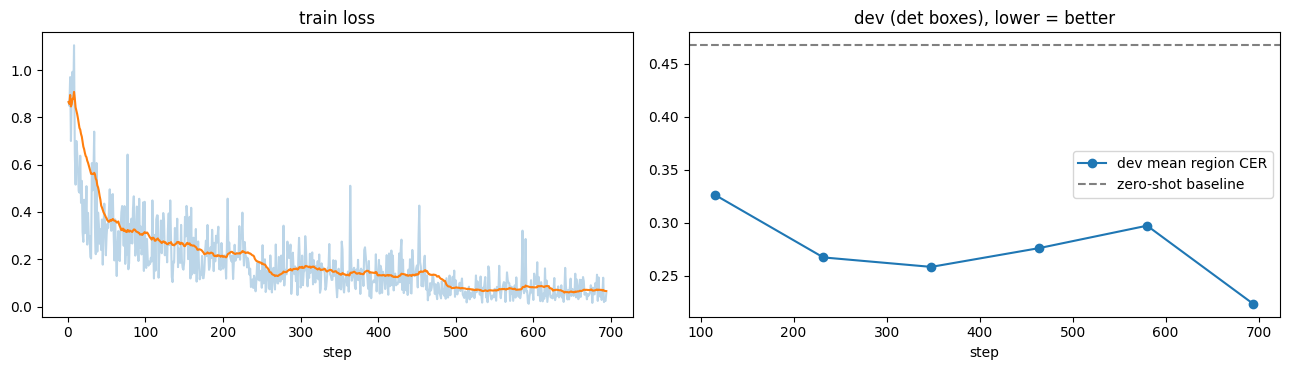

best adapter meta: 694


test_gt_best:formula:   0%|          | 0/58 [00:00<?, ?it/s]

test_gt_best:table:   0%|          | 0/4 [00:00<?, ?it/s]

,run,class,n,CER_region,CER_micro,EM,truncated,empty,loops
0,FINETUNED test/gt,formula,197,0.2355,0.2925,0.2690,2,0,1
1,FINETUNED test/gt,table,13,0.9449,0.6035,0.1538,0,0,0
2,FINETUNED test/gt,all,210,0.2794,0.3255,0.2619,2,0,1


test_det_best:formula:   0%|          | 0/58 [00:00<?, ?it/s]

test_det_best:table:   0%|          | 0/4 [00:00<?, ?it/s]

... (4 outputs left out)


Also over ALL test regions (not only scorable):


,run,class,n,CER_region,CER_micro,EM,truncated,empty,loops
0,"finetuned test/det, all regions",formula,230,0.2513,0.2778,0.2522,2,0,0
1,"finetuned test/det, all regions",table,14,0.9490,0.7221,0.1429,0,0,1
2,"finetuned test/det, all regions",all,244,0.2913,0.3397,0.2459,2,0,1



CER by source (finetuned, det, scorable):


,source,type,n,CER_region
0,school,formula,116,0.1552
1,school,table,13,0.9547
2,university,formula,81,0.3267


In [27]:
import matplotlib.pyplot as plt
h=pd.DataFrame(state['history']); e=pd.DataFrame(state['evals'])
fig,ax=plt.subplots(1,2,figsize=(13,3.8))
if len(h): ax[0].plot(h.step,h.loss,alpha=.3); ax[0].plot(h.step,h.loss.rolling(max(1,len(h)//20+1),min_periods=1).mean()); ax[0].set_title('train loss'); ax[0].set_xlabel('step')
if len(e):
    ax[1].plot(e.step,e.dev_score,'o-',label='dev mean region CER'); ax[1].axhline(BASELINE_DEV_SCORE,ls='--',c='gray',label='zero-shot baseline'); ax[1].legend(); ax[1].set_title('dev (det boxes), lower = better'); ax[1].set_xlabel('step')
plt.tight_layout(); plt.show()

assert BEST.exists(),'no best adapter (see previous cell)'
activate(BEST); print('best adapter meta:',json.loads((BEST/'best_meta.json').read_text())['step'])
TEST={}; frames=[]
for mode in ('gt','det'):
    recs=evaluate(test_rows,mode,f'test_{mode}_best'); TEST[mode]=(recs,summarize(recs)); frames.append(show(f'FINETUNED test/{mode}',TEST[mode][1]).assign(model='finetuned',mode=mode))
if RUN_BASELINE_TEST:
    brecs=evaluate(test_rows,'det','test_det_baseline',adapter=False); bsum=summarize(brecs); frames.append(show('ZERO-SHOT base test/det',bsum).assign(model='zero-shot',mode='det'))
    activate(BEST)
pd.concat(frames).to_csv(ROOT/'test_metrics.csv',index=False)
print('\nAlso over ALL test regions (not only scorable):'); _=show('finetuned test/det, all regions',summarize(TEST['det'][0],scorable_only=False))
print('\nCER by source (finetuned, det, scorable):')
rs=[x for x in TEST['det'][0] if x['scorable']]
display(pd.DataFrame([{'source':s,'type':k,'n':len(xs),'CER_region':np.mean([lev(norm(x['reference']),norm(x['prediction']))/max(1,len(norm(x['reference']))) for x in xs])}
    for (s,k),xs in {(s,k):[x for x in rs if x['source']==s and x['type']==k] for s in {x['source'] for x in rs} for k in TASKS}.items() if xs]).round(4))

## 14. Аналіз помилок: найгірші приклади (картинка / еталон / прогноз)
Тут видно, чи проблема в читанні почерку, у форматі (`|`, LaTeX vs unicode), у кропі, чи у відсічці довжини.

truncated: 2 | loops: 0 | empty: 0


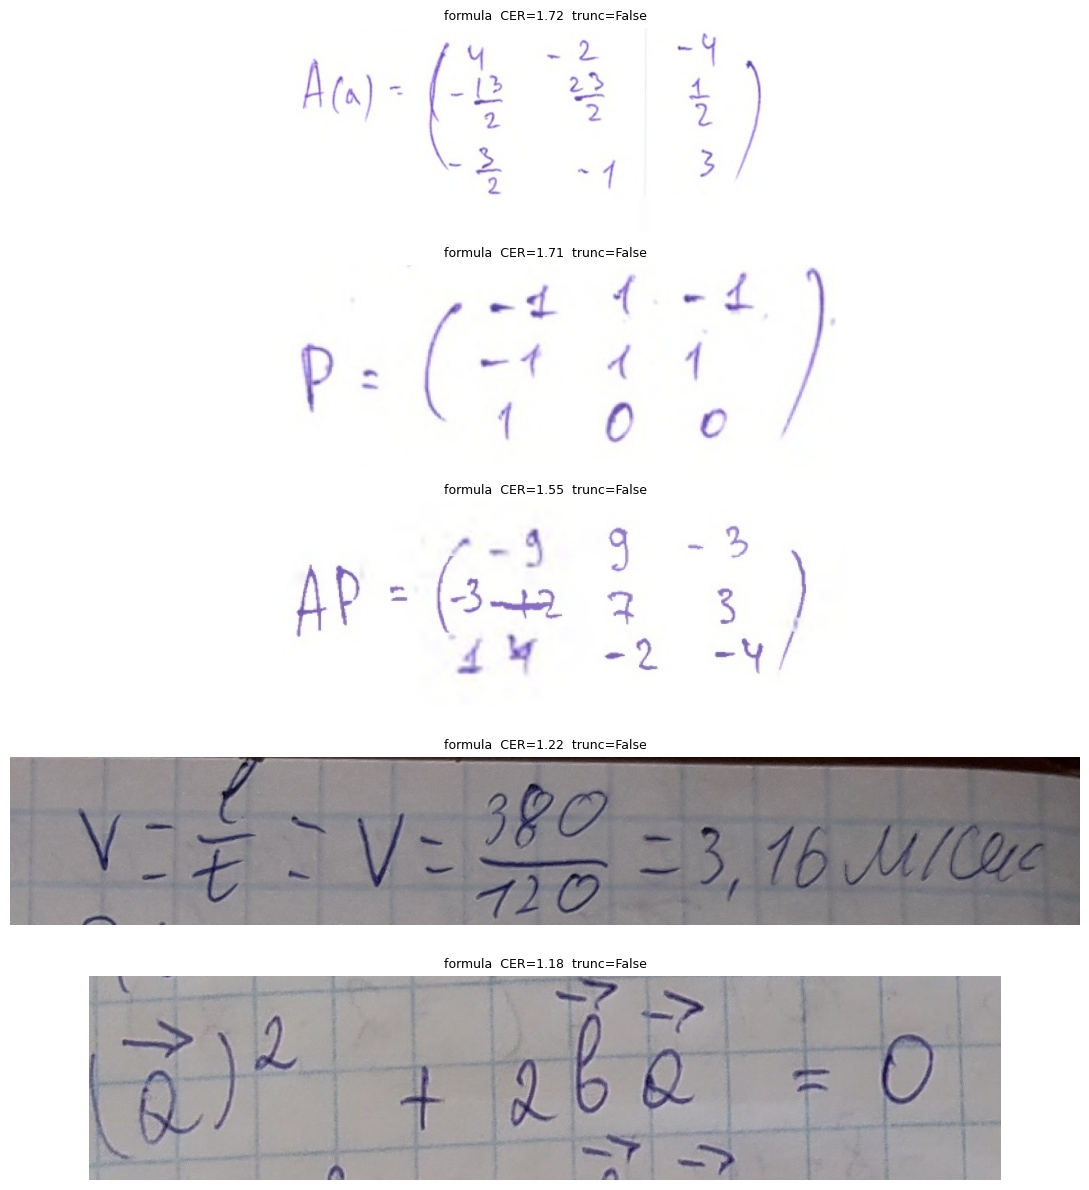

[formula] CER=1.72
  REF :'A(a) = ( 4 -2 -4 / -13/2 23/2 1/2 / -3/2 -1 3 )'
  PRED:'A(a) = \\begin{pmatrix} -4 & -2 & -4 \\\\ -\\frac{13}{2} & \\frac{23}{2} & \\frac{1}{2} \\\\ -\\frac{3}{2} & -1 & 3 \\end{pmatrix}'
[formula] CER=1.71
  REF :'P = (-1 1 -1; -1 1 1; 1 0 0)'
  PRED:'P = \\begin{pmatrix} -1 & 1 & -1 \\\\ -1 & 1 & 1 \\\\ 1 & 0 & 0 \\end{pmatrix}'
[formula] CER=1.55
  REF :'AP = (-9 9 -3/ -3 ~~-12~~ 7 3/14-2-4)'
  PRED:'AP = \\begin{pmatrix} -9 & 9 & -3 \\\\ -3 & 7 & 3 \\\\ 14 & -2 & -4 \\end{pmatrix}'
[formula] CER=1.22
  REF :'v=e/t=v=380/120=3.16 м/сек.'
  PRED:'V = \\frac{l}{t} = V = \\frac{380}{120} = 3,16 м/с'
[formula] CER=1.18
  REF :'(→a)^2 + →2ba = 0'
  PRED:'(\\vec{a})^2 + 2\\vec{b} \\vec{a} = 0'


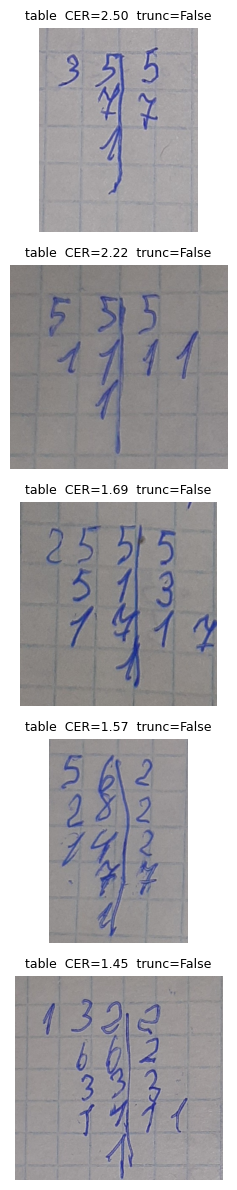

[table] CER=2.50
  REF :'35 | 5\n7 | 7\n1 |'
  PRED:'\\begin{array}{r|l} 35 & 5 \\\\ 7 & 7 \\\\ 1 & \\end{array}'
[table] CER=2.22
  REF :'55 | 5\n11 | 11\n  1 |'
  PRED:'\\begin{array}{r|l} 55 & 5 \\\\ 11 & 11 \\\\   1 & \\end{array}'
[table] CER=1.69
  REF :'255 | 5\n51 | 5\n17 | 17\n1 |'
  PRED:'\\begin{array}{r|l} 255 & 5 \\\\ 51 & 3 \\\\ 17 & 17\\\\  1 & \\end{array}'
[table] CER=1.57
  REF :'56 | 2\n28 | 2\n14 | 2\n7 | 7\n1 |'
  PRED:'\\begin{array}{r|l} 56 & 2 \\\\ 28 & 2 \\\\ 14 & 2\\\\ 7 & 7 \\\\  1 & \\end{array}'
[table] CER=1.45
  REF :'132 | 2\n66 | 2\n33 | 3\n11 | 11\n1 |'
  PRED:'\\begin{array}{r|l} 132 & 2 \\\\ 66 & 2 \\\\ 33 & 2  \\\\ 11 & 11\\\\1 & \\end{array}'


In [28]:
recs=TEST['det'][0]; scored=[]
for x in recs:
    if not x['scorable']: continue
    a,b=norm(x['reference']),norm(x['prediction']); scored.append((lev(a,b)/max(1,len(a)),x))
scored.sort(key=lambda t:-t[0])
print('truncated:',sum(x['truncated'] for _,x in scored),'| loops:',sum(has_loop(x['prediction']) for _,x in scored),'| empty:',sum(not x['prediction'] for _,x in scored))
for kind in TASKS:
    worst=[t for t in scored if t[1]['type']==kind][:5]
    if not worst: continue
    fig,axs=plt.subplots(len(worst),1,figsize=(11,2.4*len(worst)))
    for a_,(c,x) in zip(np.atleast_1d(axs),worst):
        a_.imshow(load_view(ROW_BY_KEY[x['key']],'det')); a_.axis('off'); a_.set_title(f"{kind}  CER={c:.2f}  trunc={x['truncated']}",fontsize=9)
    plt.tight_layout(); plt.show()
    for c,x in worst: print(f'[{kind}] CER={c:.2f}\n  REF :{x["reference"][:260]!r}\n  PRED:{x["prediction"][:260]!r}')

## 15. Перевірка в **bf16 без квантування** (як працюватиме на H100)
QLoRA тренується на 4-bit базі, а в пайплайні модель можна тримати в bf16 (8B ≈ 16 ГБ — влізає в H100 з великим запасом). Ця клітинка заново оцінює той самий адаптер на bf16-базі, щоб побачити реальну цифру для деплою. Якщо вона помітно гірша за 4-bit — інференс у пайплайні краще робити теж у 4-bit (NF4) або домерджити й перевірити.

In [29]:
BF16_RESULT=None
if RUN_BF16_CHECK and BF16:
    del model, base; gc.collect(); torch.cuda.empty_cache()
    base16=Qwen3VLForConditionalGeneration.from_pretrained(MODEL_ID,torch_dtype=torch.bfloat16,device_map={'':0},attn_implementation='sdpa')
    model=PeftModel.from_pretrained(base16,str(BEST)); model.eval()
    recs16=evaluate(test_rows,'det','test_det_best_bf16base'); BF16_RESULT=summarize(recs16); _=show('FINETUNED on bf16 base, test/det',BF16_RESULT)
    print('4-bit-trained adapter on 4-bit base vs bf16 base (mean region CER, test/det):',round(selection_score(TEST['det'][1]),4),'vs',round(selection_score(BF16_RESULT),4))
    if MERGE_EXPORT:
        merged=model.merge_and_unload(); out=ROOT/'merged_bf16'; merged.save_pretrained(out,safe_serialization=True); processor.save_pretrained(out); print('merged model saved to',out)
else: print('bf16 check skipped (RUN_BF16_CHECK=False or no bf16).')

Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

OutOfMemoryError: CUDA out of memory. Tried to allocate 96.00 MiB. GPU 0 has a total capacity of 22.03 GiB of which 15.12 MiB is free. Including non-PyTorch memory, this process has 22.01 GiB memory in use. Of the allocated memory 21.52 GiB is allocated by PyTorch, and 261.89 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

## 16. Експорт для команди: `infer_formula_table.py` + `handoff.json`
Скрипт містить **той самий `budget_resize`**, що й тренування (`PREP_SRC`), ті самі промпти й бюджети генерації, тож препроцесинг у пайплайні не розійдеться з тим, на чому вчили. Для кропів від PP-DocLayoutV3 рекомендовано розширювати бокс на ~4 % (клас `expand_box` вже є), бо тренування бачило розширення до 12 %.

In [ ]:
INFER_TEMPLATE = r"""
# Auto-generated by RUKOPYS 06 notebook. Same preprocessing / prompts / decoding as training+evaluation.
import json, torch
from PIL import Image
from transformers import AutoProcessor, Qwen3VLForConditionalGeneration, BitsAndBytesConfig

__PREP__

CFG = json.loads(__CFG__)

class FormulaTableOCR:
    # adapter_dir: LoRA adapter folder (best_adapter) OR a merged model folder (set merged=True). quant4=False -> bf16 base (default, H100).
    def __init__(self, adapter_dir, merged=False, quant4=False, device='cuda'):
        src = adapter_dir if merged else CFG['model_id']
        self.processor = AutoProcessor.from_pretrained(CFG['model_id'])
        configure_processor(self.processor, max_tokens=CFG['processor_max_tokens'])
        self.tok = self.processor.tokenizer
        kw = dict(torch_dtype=torch.bfloat16, device_map={'': 0}, attn_implementation='sdpa')
        if quant4:
            kw['quantization_config'] = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4', bnb_4bit_compute_dtype=torch.bfloat16,
                                                           bnb_4bit_use_double_quant=True, llm_int8_skip_modules=['visual', 'lm_head'])
        model = Qwen3VLForConditionalGeneration.from_pretrained(src, **kw)
        if not merged:
            from peft import PeftModel
            model = PeftModel.from_pretrained(model, adapter_dir)
        self.model = model.eval()
        self.im_end = self.tok.convert_tokens_to_ids('<|im_end|>')

    @staticmethod
    def expand_box(box, W, H, frac=None):
        frac = CFG['infer_expand_frac'] if frac is None else frac
        x1, y1, x2, y2 = box; w, h = x2 - x1, y2 - y1
        return [max(0, x1 - frac * w), max(0, y1 - frac * h), min(W, x2 + frac * w), min(H, y2 + frac * h)]

    def _text(self, kind):
        m = [{'role': 'user', 'content': [{'type': 'image'}, {'type': 'text', 'text': CFG['prompts'][kind]}]}]
        return self.processor.apply_chat_template(m, tokenize=False, add_generation_prompt=True)

    @torch.inference_mode()
    def transcribe(self, crops, kinds, batch_size=8):
        # crops: list of PIL images (already cropped from the page); kinds: list of 'formula' | 'table'
        out = [None] * len(crops)
        for kind in ('formula', 'table'):
            idx = sorted([i for i, k in enumerate(kinds) if k == kind], key=lambda i: crops[i].width * crops[i].height)
            for s in range(0, len(idx), batch_size):
                ch = idx[s:s + batch_size]
                imgs = [budget_resize(crops[i], CFG['tok_min'][kind], CFG['tok_max'][kind]) for i in ch]
                self.tok.padding_side = 'left'
                b = self.processor(text=[self._text(kind)] * len(ch), images=imgs, padding=True, return_tensors='pt')
                b.pop('token_type_ids', None); b = b.to(self.model.device)
                g = self.model.generate(**b, max_new_tokens=CFG['gen_tokens'][kind], do_sample=False, use_cache=True, pad_token_id=self.tok.pad_token_id)
                for i, t in zip(ch, self.tok.batch_decode(g[:, b['input_ids'].shape[1]:], skip_special_tokens=True)): out[i] = t.strip()
        return out
"""
INFER_CFG={'model_id':MODEL_ID,'prompts':PROMPTS,'tok_min':TOK_MIN,'tok_max':TOK_MAX,'gen_tokens':GEN_TOKENS,'processor_max_tokens':max(TOK_MAX.values())*2,'infer_expand_frac':0.04}
infer_src=INFER_TEMPLATE.replace('__PREP__',PREP_SRC).replace('__CFG__',repr(json.dumps(INFER_CFG,ensure_ascii=False)))
compile(infer_src,'infer_formula_table.py','exec')           # syntax check
(ROOT/'infer_formula_table.py').write_text(infer_src,encoding='utf-8')

handoff={'task':'formula+table OCR (Stage 2, Qwen branch)','base_model':MODEL_ID,'adapter_dir':str(BEST),'best_step':state['best_step'],
 'dataset_revision':REVISION,'metadata_sha256':meta_sha,'split_file':str(ROOT/'split.json'),'normalizer_used_for_metrics':NORMALIZER_NAME,
 'prompts':PROMPTS,'preprocessing':{'tok_min':TOK_MIN,'tok_max':TOK_MAX,'unit_px':32,'note':'keep aspect ratio, sides multiple of 32'},
 'decoding':{'do_sample':False,'max_new_tokens':GEN_TOKENS},'recommended_box_expand_frac':0.04,
 'train':{'epochs':EPOCHS,'eff_batch':EFF_BATCH,'lr_llm':LR_LLM,'lr_vision':LR_VISION,'lora_r':LORA_R,'use_silver':USE_SILVER,'n_train':len(train_rows)},
 'zero_shot_dev_score':BASELINE_DEV_SCORE,'best_dev_score':state['best_score'],
 'test_metrics_4bit_base':{m:TEST[m][1] for m in TEST},'test_metrics_bf16_base':BF16_RESULT,
 'caveats':['dev was used to pick the checkpoint; test was used once for reporting','metrics are per-region CER, not the full Kaggle score (which also includes detection, classification and PageCER)',
            'normalizer is '+NORMALIZER_NAME,'only valid with the SAME base model id as above']}
(ROOT/'handoff.json').write_text(json.dumps(handoff,indent=2,ensure_ascii=False,default=str),encoding='utf-8')
print('saved:',ROOT/'infer_formula_table.py','\nsaved:',ROOT/'handoff.json')
print('\nUsage in the pipeline:\n  from infer_formula_table import FormulaTableOCR\n  ocr = FormulaTableOCR("%s")\n  texts = ocr.transcribe([crop1, crop2], ["formula","table"])'%BEST)

## Що робити далі
1. **Якщо dev/test CER не краще за zero-shot** — дивіться клітинки 6 (аудит) і 14 (помилки): типово винні формат GT (`|`, LaTeX vs unicode), обрізання (`truncated`) або надто малий бюджет токенів для таблиць.
2. **Якщо приріст є, але є що додати:** (а) `USE_SILVER=True` і порівняти dev з/без (окремий `ROOT`!); (б) збільшити `EPOCHS` лише якщо dev-крива ще падає; (в) для довгих таблиць підняти `TOK_MAX['table']`.
3. **Інтеграція:** `handoff.json` + `best_adapter/` + `infer_formula_table.py`. Подайте кропи від PP-DocLayoutV3 з розширенням боксу ~4 %, тип (`formula`/`table`) — із детектора.
4. **Не забудьте:** фінальний Kaggle-скор = 15% detection + 5% класифікація + 30% region CER + **50% PageCER**; ця модель впливає на два останні лише на формулах/таблицях. Прогоніть повний пайплайн на локальному дебагері офіційної метрики.
5. Після дедлайнових експериментів можна донавчити фінальний адаптер на `train+dev` з тими самими гіперпараметрами і кроками (ставити новий `ROOT`), але тоді `dev` більше не буде чесним.